# Reject Option Classification (ROC) - fairness evaluation on Adult, German Credit and COMPAS

Assignment 4, run 3 (generated with Genie Code, written from scratch).

**Algorithm:** Reject Option based Classification, F. Kamiran, A. Karim, X. Zhang, *Decision Theory for Discrimination-Aware Classification*, IEEE ICDM 2012. Category: **post-processing**.

**Idea:** a probabilistic classifier is uncertain near its decision boundary. Inside a *critical region* around the threshold (|p - theta| <= omega), instances of the unprivileged group get the favourable label and instances of the privileged group get the unfavourable label. Outside the region the normal decision rule is kept. theta and omega are tuned on a validation split so that the fairness constraint |DP_Diff| <= 0.05 holds with the highest balanced accuracy (the same search AIF360's `RejectOptionClassification` performs).

**Pipeline**
1. Load the datasets, define binary protected attribute S (1 = privileged) and favourable label Y = 1.
2. Fairness of the **original labels** (before any mitigation or classifier): DP_Diff, DIR, Consistency.
3. Stratified 70/30 train/test split (stratified on Y x S); the training part is split again 70/30 into fit/validation.
4. Train logistic regression on the fit split (baseline, threshold 0.5).
5. Tune ROC (theta, omega) on the validation split; apply it to the test-set scores.
6. Report DP_Diff, DIR, Consistency, accuracy, balanced accuracy and F1 on the test set for baseline and ROC; 5 seeds, mean +- std.

Metric conventions (as AIF360): DP_Diff = P(Yhat=1 | S=0) - P(Yhat=1 | S=1) (0 = fair, negative = unprivileged disadvantaged); DIR = P(Yhat=1 | S=0) / P(Yhat=1 | S=1) (1 = fair, 0.8 - 1.25 acceptable); Consistency = 1 - mean_i |yhat_i - mean of yhat over the k = 5 nearest neighbours of x_i| (1 = similar individuals treated alike).

In [0]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Data folder: env var DATA_DIR, otherwise the assignment folder on Databricks
DATA_DIR = os.environ.get('DATA_DIR', '/Workspace/Users/ehab.wasel@ssc4tbi.nl/fairness_assignment4')
OUT_DIR = os.environ.get('OUT_DIR', os.getcwd())
SEEDS = [0, 1, 2, 3, 42]
DP_BOUND = 0.05   # fairness constraint used to tune ROC
K_NN = 5          # neighbours for consistency
print('DATA_DIR =', DATA_DIR)

DATA_DIR = /Workspace/Users/ehab.wasel@ssc4tbi.nl/fairness_assignment4


In [0]:
# Each loader returns X (features, protected attribute removed), y (1 = favourable) and s (1 = privileged).

def load_adult():
    df = pd.read_csv(f'{DATA_DIR}/adult.csv').replace('?', np.nan).dropna()
    y = (df['income'].str.strip() == '>50K').astype(int).values      # favourable: income > 50K
    s = (df['sex'] == 'Male').astype(int).values                     # privileged: male
    X = df.drop(columns=['income', 'sex', 'education', 'fnlwgt'])    # education duplicates education.num
    return X, y, s

def load_german():
    df = pd.read_csv(f'{DATA_DIR}/statlog+german+credit+data/german.data', sep=' ', header=None)
    df.columns = [f'a{i+1}' for i in range(20)] + ['credit']
    y = (df['credit'] == 1).astype(int).values                       # favourable: good credit (1)
    s = (df['a13'] > 25).astype(int).values                          # attribute 13 = age; privileged: age > 25
    X = df.drop(columns=['credit', 'a13'])
    return X, y, s

def load_compas():
    df = pd.read_csv(f'{DATA_DIR}/propublica_data_for_fairml.csv')
    y = (df['Two_yr_Recidivism'] == 0).astype(int).values            # favourable: no two-year recidivism
    s = (df['African_American'] == 0).astype(int).values             # privileged: not African-American
    X = df.drop(columns=['Two_yr_Recidivism', 'score_factor', 'African_American'])  # score_factor = COMPAS score, excluded
    return X, y, s

DATASETS = {'Adult': load_adult, 'German': load_german, 'COMPAS': load_compas}
for name, ld in DATASETS.items():
    X, y, s = ld()
    print(f'{name:7s} rows={len(y):6d} features={X.shape[1]:3d} P(Y=1)={y.mean():.3f} P(S=1)={s.mean():.3f}')

Adult   rows= 30162 features= 11 P(Y=1)=0.249 P(S=1)=0.676
German  rows=  1000 features= 19 P(Y=1)=0.700 P(S=1)=0.810
COMPAS  rows=  6172 features=  9 P(Y=1)=0.545 P(S=1)=0.486


In [0]:
def make_encoder(X):
    cat = [c for c in X.columns if X[c].dtype == object]
    num = [c for c in X.columns if c not in cat]
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
                              ('num', StandardScaler(), num)])

def dp_diff(yhat, s):
    return yhat[s == 0].mean() - yhat[s == 1].mean()

def disparate_impact(yhat, s):
    return yhat[s == 0].mean() / yhat[s == 1].mean()

def consistency(X_enc, yhat, k=K_NN):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X_enc)
    idx = nn.kneighbors(X_enc, return_distance=False)[:, 1:]   # drop the point itself
    return 1 - np.mean(np.abs(yhat - yhat[idx].mean(axis=1)))

def roc_predict(p, s, theta, omega):
    """Reject Option Classification: inside |p - theta| <= omega, unprivileged -> 1, privileged -> 0."""
    yhat = (p > theta).astype(int)
    critical = np.abs(p - theta) <= omega
    yhat[critical & (s == 0)] = 1
    yhat[critical & (s == 1)] = 0
    return yhat

def fit_roc(p, y, s, bound=DP_BOUND, thetas=np.linspace(0.05, 0.95, 91), omegas=np.linspace(0, 0.5, 51)):
    """Grid search on validation data: max balanced accuracy s.t. |DP_Diff| <= bound;
    if no setting meets the bound, take the one with the smallest |DP_Diff|."""
    best = None
    for t in thetas:
        for w in omegas:
            yh = roc_predict(p, s, t, w)
            d = dp_diff(yh, s)
            ok = abs(d) <= bound
            key = (ok, balanced_accuracy_score(y, yh) if ok else -abs(d))
            if best is None or key > best[0]:
                best = (key, t, w)
    return best[1], best[2], best[0][0]

In [0]:
# ROC rule: theta 0.5, omega 0.1 -> p 0.45 (unpriv) flips to 1, p 0.55 (priv) flips to 0, others unchanged
p = np.array([0.20, 0.45, 0.55, 0.80]); s_ = np.array([0, 0, 1, 1])
assert list(roc_predict(p, s_, 0.5, 0.1)) == [0, 1, 0, 1]
# omega 0 -> plain threshold classifier
assert list(roc_predict(p, s_, 0.5, 0.0)) == [0, 0, 1, 1]
# metrics: unpriv rate 0.5, priv rate 1.0 -> DP -0.5, DIR 0.5
yh = np.array([1, 0, 1, 1])
assert np.isclose(dp_diff(yh, s_), -0.5) and np.isclose(disparate_impact(yh, s_), 0.5)
# consistency of a constant prediction is 1
assert np.isclose(consistency(np.random.RandomState(0).rand(20, 3), np.ones(20)), 1.0)
print('all sanity tests passed')

all sanity tests passed


In [0]:
before = []
for name, ld in DATASETS.items():
    X, y, s = ld()
    X_enc = make_encoder(X).fit_transform(X)
    before.append(dict(Dataset=name, DP_Diff=dp_diff(y, s), DIR=disparate_impact(y, s), Consistency=consistency(X_enc, y)))
before = pd.DataFrame(before).set_index('Dataset')
display(before.round(3).reset_index())

Dataset,DP_Diff,DIR,Consistency
Adult,-0.2,0.362,0.805
German,-0.149,0.795,0.675
COMPAS,-0.14,0.773,0.603


In [0]:
def run_one(name, loader, seed):
    X, y, s = loader()
    # stratified 70/30 train/test split on label x group
    X_tr, X_te, y_tr, y_te, s_tr, s_te = train_test_split(X, y, s, test_size=0.3, stratify=2 * y + s, random_state=seed)
    # validation split inside the training data, used only to tune ROC
    X_fit, X_val, y_fit, y_val, s_fit, s_val = train_test_split(X_tr, y_tr, s_tr, test_size=0.3, stratify=2 * y_tr + s_tr, random_state=seed)

    enc = make_encoder(X).fit(X_fit)
    clf = LogisticRegression(C=1.0, max_iter=2000).fit(enc.transform(X_fit), y_fit)

    p_val = clf.predict_proba(enc.transform(X_val))[:, 1]
    theta, omega, met = fit_roc(p_val, y_val, s_val)

    E_te = enc.transform(X_te)
    p_te = clf.predict_proba(E_te)[:, 1]
    rows = []
    for stage, yhat in [('Baseline', (p_te > 0.5).astype(int)), ('ROC', roc_predict(p_te, s_te, theta, omega))]:
        rows.append(dict(Dataset=name, Seed=seed, Stage=stage,
                         DP_Diff=dp_diff(yhat, s_te), DIR=disparate_impact(yhat, s_te), Consistency=consistency(E_te, yhat),
                         Accuracy=accuracy_score(y_te, yhat), BalancedAcc=balanced_accuracy_score(y_te, yhat), F1=f1_score(y_te, yhat),
                         theta=theta, omega=omega, BoundMetOnVal=met))
    return rows

t0 = time.time()
results = pd.DataFrame([r for name, ld in DATASETS.items() for sd in SEEDS for r in run_one(name, ld, sd)])
print(f'done in {time.time() - t0:.0f} s')
display(results.round(3))

done in 32 s


Dataset,Seed,Stage,DP_Diff,DIR,Consistency,Accuracy,BalancedAcc,F1,theta,omega,BoundMetOnVal
Adult,0,Baseline,-0.182,0.316,0.95,0.849,0.77,0.669,0.21,0.13,true
Adult,0,ROC,-0.047,0.873,0.898,0.786,0.786,0.646,0.21,0.13,true
Adult,1,Baseline,-0.186,0.296,0.942,0.851,0.771,0.672,0.23,0.14,true
Adult,1,ROC,-0.05,0.862,0.9,0.797,0.791,0.656,0.23,0.14,true
Adult,2,Baseline,-0.183,0.307,0.944,0.844,0.762,0.656,0.2,0.13,true
Adult,2,ROC,-0.029,0.924,0.893,0.777,0.786,0.642,0.2,0.13,true
Adult,3,Baseline,-0.197,0.297,0.948,0.846,0.772,0.668,0.21,0.13,true
Adult,3,ROC,-0.05,0.874,0.895,0.777,0.789,0.644,0.21,0.13,true
Adult,42,Baseline,-0.187,0.304,0.947,0.848,0.769,0.667,0.23,0.14,true
Adult,42,ROC,-0.059,0.835,0.904,0.798,0.788,0.654,0.23,0.14,true


In [0]:
cols = ['DP_Diff', 'DIR', 'Consistency', 'Accuracy', 'BalancedAcc', 'F1', 'theta', 'omega']
summary = results.groupby(['Dataset', 'Stage'], sort=False)[cols].agg(['mean', 'std']).round(3)
orig = before.copy(); orig['Stage'] = 'Original labels'
compare = pd.concat([orig.reset_index().set_index(['Dataset', 'Stage']),
                     results.groupby(['Dataset', 'Stage'], sort=False)[['DP_Diff', 'DIR', 'Consistency', 'Accuracy', 'BalancedAcc', 'F1']].mean()])
compare = compare.reindex([(d, st) for d in DATASETS for st in ['Original labels', 'Baseline', 'ROC']]).round(3)
display(compare.reset_index())
display(summary.reset_index())

Dataset,Stage,DP_Diff,DIR,Consistency,Accuracy,BalancedAcc,F1
Adult,Original labels,-0.2,0.362,0.805,null,null,null
Adult,Baseline,-0.187,0.304,0.946,0.848,0.769,0.667
Adult,ROC,-0.047,0.874,0.898,0.787,0.788,0.649
German,Original labels,-0.149,0.795,0.675,null,null,null
German,Baseline,-0.092,0.884,0.772,0.751,0.665,0.831
German,ROC,0.037,1.055,0.693,0.721,0.706,0.788
COMPAS,Original labels,-0.14,0.773,0.603,null,null,null
COMPAS,Baseline,-0.265,0.651,0.987,0.671,0.662,0.718
COMPAS,ROC,-0.067,0.879,0.908,0.658,0.657,0.677


"('Dataset', '')","('Stage', '')","('DP_Diff', 'mean')","('DP_Diff', 'std')","('DIR', 'mean')","('DIR', 'std')","('Consistency', 'mean')","('Consistency', 'std')","('Accuracy', 'mean')","('Accuracy', 'std')","('BalancedAcc', 'mean')","('BalancedAcc', 'std')","('F1', 'mean')","('F1', 'std')","('theta', 'mean')","('theta', 'std')","('omega', 'mean')","('omega', 'std')"
Adult,Baseline,-0.187,0.006,0.304,0.008,0.946,0.003,0.848,0.003,0.769,0.004,0.667,0.006,0.216,0.013,0.134,0.005
Adult,ROC,-0.047,0.011,0.874,0.032,0.898,0.004,0.787,0.01,0.788,0.002,0.649,0.006,0.216,0.013,0.134,0.005
German,Baseline,-0.092,0.059,0.884,0.077,0.772,0.032,0.751,0.026,0.665,0.031,0.831,0.02,0.646,0.07,0.07,0.025
German,ROC,0.037,0.094,1.055,0.154,0.693,0.022,0.721,0.024,0.706,0.021,0.788,0.025,0.646,0.07,0.07,0.025
COMPAS,Baseline,-0.265,0.032,0.651,0.035,0.987,0.002,0.671,0.007,0.662,0.007,0.718,0.005,0.56,0.012,0.06,0.01
COMPAS,ROC,-0.067,0.041,0.879,0.072,0.908,0.01,0.658,0.014,0.657,0.014,0.677,0.013,0.56,0.012,0.06,0.01


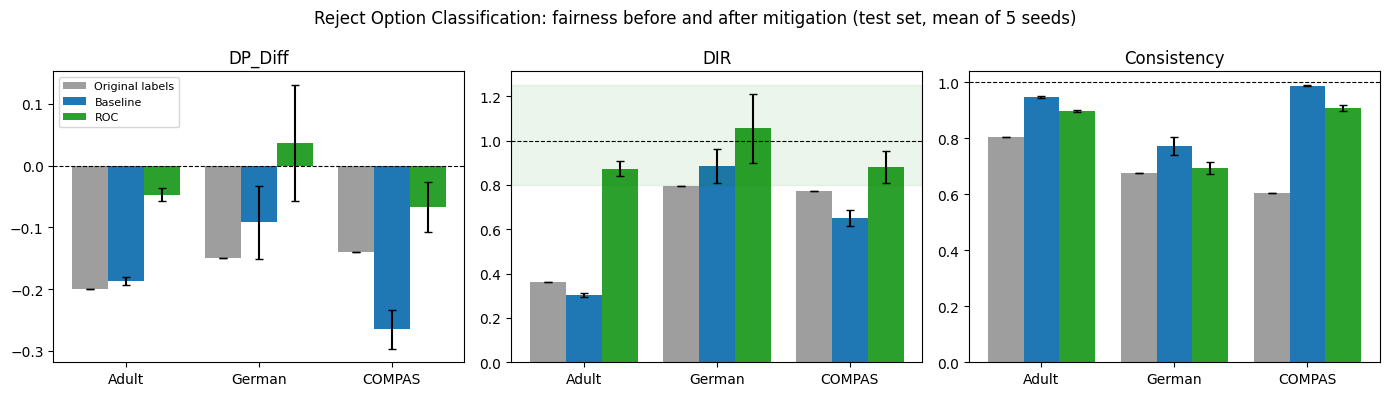

In [0]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
stages = ['Original labels', 'Baseline', 'ROC']
colors = ['#9e9e9e', '#1f77b4', '#2ca02c']
for ax, metric, ideal in zip(axes, ['DP_Diff', 'DIR', 'Consistency'], [0, 1, 1]):
    x = np.arange(len(DATASETS))
    for i, st in enumerate(stages):
        vals = [compare.loc[(d, st), metric] for d in DATASETS]
        errs = [0 if st == 'Original labels' else summary.loc[(d, st), (metric, 'std')] for d in DATASETS]
        ax.bar(x + (i - 1) * 0.27, vals, 0.27, yerr=errs, label=st, color=colors[i], capsize=3)
    ax.axhline(ideal, color='k', ls='--', lw=0.8)
    if metric == 'DIR':
        ax.axhspan(0.8, 1.25, color='green', alpha=0.08)
    ax.set_xticks(x); ax.set_xticklabels(list(DATASETS)); ax.set_title(metric)
axes[0].legend(fontsize=8)
fig.suptitle('Reject Option Classification: fairness before and after mitigation (test set, mean of 5 seeds)')
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'roc_before_after.png'), dpi=150)
plt.show()

## Parameter settings
| Parameter | Value |
| --- | --- |
| Classifier | Logistic regression, L2, C = 1.0, lbfgs, max_iter = 2000 |
| Encoding | One-hot (categorical) + standardisation (numerical), fitted on the fit split only |
| Protected attribute | Not used as a model feature; used only by the ROC post-processor |
| Splits | Train/test 70/30 stratified on Y x S; train split again 70/30 into fit/validation |
| ROC search | theta in [0.05, 0.95] step 0.01, omega in [0, 0.5] step 0.01; maximise balanced accuracy s.t. \|DP_Diff\| <= 0.05 on validation |
| Consistency | k = 5 nearest neighbours in the encoded feature space |
| Seeds | 0, 1, 2, 3, 42 |
| Adult | rows with "?" removed; `education`, `fnlwgt` dropped; S = sex (male privileged) |
| German | S = age > 25 (privileged); Y = good credit |
| COMPAS | S = not African-American (privileged); Y = no two-year recidivism; `score_factor` excluded |